In [2]:
import pandas as pd
import numpy as np
import time
import random
from scipy.optimize import Bounds, minimize
from openpyxl import load_workbook, Workbook

# Read input data
data = pd.read_excel('data/input42u.xlsx')
a = data['a'].values
b = data['b'].values
c = data['c'].values
Minimum_Capacity = data['pmin'].values
Maximum_Capacity = data['pmax'].values
ramp_up = data['rampup'].values
ramp_down = data['rampdown'].values
Unit = data['Unit'].values

penalty_factor = 1e6

# Read power demand data
power_demand_data = pd.read_excel('data/power_demand42u.xlsx')
power_demand = power_demand_data['load'].values

# Initialize an empty list to store results for each demand
all_outputs = []

# Define function to calculate power produced
def calculate_power(P):
    return np.sum(P)

# Define function to calculate fuel cost with penalty
def calculate_fuel_cost_with_penalty(P, a, b, c, demand):
    squaredP = np.multiply(P, P)
    Fuel_Cost = np.divide(np.add(a, np.multiply(b, P) + np.multiply(c, squaredP)), 1000)

    # Penalty for power balance constraint violation
    power_difference = np.sum(P) - demand
    penalty_term = penalty_factor * abs(power_difference)

    total_Fuel_Cost = np.sum(Fuel_Cost) + penalty_term
    return total_Fuel_Cost

# Define zero Hessian for linear/quasi-linear problems
def hess_zero(x):
    return np.zeros((len(x), len(x)))

# Interior point method with explicit zero Hessian
def interior_point_method(objective_func, constraints, initial_guess, bounds):
    result = minimize(
        fun=objective_func,
        jac=constraints,
        hess=hess_zero,  # 👈 avoids warning by explicitly setting Hessian
        x0=initial_guess,
        bounds=bounds,
        method='trust-constr'
    )
    return result.x

# Powell's Dog Leg Method with chaotic search
def powells_dog_leg_with_chaos(func, grad_func, x0, trust_region_radius=0.1, tol=1e-6, max_iter=100, chaotic_step_prob=0.1, bounds=None):
    x = x0.copy()
    p = -grad_func(x)
    k = 0
    while np.linalg.norm(p) > tol and k < max_iter:
        # Apply chaotic step with a certain probability
        if random.random() < chaotic_step_prob:
            # Chaotic search direction
            p_chaotic = np.array([chaotic_map(xi) for xi in p])
            p_chaotic /= np.linalg.norm(p_chaotic)  # Normalize chaotic step
            p = p_chaotic
        
        # Rest of the algorithm remains the same
        # Calculate the Newton direction
        B = np.linalg.inv(np.atleast_2d(hessian(x)))
        newton_step = -np.dot(B, grad_func(x))
        
        # Calculate the Cauchy point
        if np.dot(grad_func(x), np.dot(B, grad_func(x))) <= 0:
            tau = 1
        else:
            tau = min(np.linalg.norm(grad_func(x)) ** 3 / (trust_region_radius * np.dot(grad_func(x), np.dot(B, grad_func(x)))), 1)
        cauchy_point = -tau * trust_region_radius * grad_func(x) / np.linalg.norm(grad_func(x))
        
        # Calculate the dog leg step
        if np.linalg.norm(newton_step) <= trust_region_radius:
            p = newton_step
        elif np.linalg.norm(cauchy_point) >= trust_region_radius:
            p = (trust_region_radius / np.linalg.norm(grad_func(x))) * grad_func(x)
        else:
            u = cauchy_point - newton_step
            a = np.dot(u, u)
            b = 2 * np.dot(u, newton_step - cauchy_point)
            c = np.dot(newton_step - cauchy_point, newton_step - cauchy_point) - trust_region_radius ** 2
            tau = (-b + np.sqrt(b ** 2 - 4 * a * c)) / (2 * a)
            p = cauchy_point + tau * u
        
        # Perform line search to find the optimal step size using backtracking line search
        alpha = 1.0  # Initial step size
        c1 = 0.5  # Armijo condition parameter
        while func(x + alpha * p) > func(x) + c1 * alpha * np.dot(grad_func(x), p):
            alpha *= 0.5  # Reduce step size
        x = x + alpha * p
        k += 1
        
    return x

# Define chaotic function
def chaotic_map(x, alpha=1.0):
    # Define your chaotic map, for example logistic map
    return alpha * x * (1 - x)

# Define function to calculate gradient
def grad_func(x):
    # Gradient calculation based on your objective function
    # Example:
    grad = np.zeros_like(x)
    # Calculate gradient for each variable
    # For example:
    # grad[0] = derivative_of_objective_function_wrt_x0
    # grad[1] = derivative_of_objective_function_wrt_x1
    return grad

# Define function to calculate Hessian matrix
def hessian(x):
    # Hessian calculation based on your objective function
    # Example:
    n = len(x)
    hess = np.zeros((n, n))
    # Calculate Hessian for each pair of variables
    # For example:
    # hess[0, 0] = second_derivative_of_objective_function_wrt_x0x0
    # hess[0, 1] = second_derivative_of_objective_function_wrt_x0x1
    # hess[1, 0] = second_derivative_of_objective_function_wrt_x1x0 (usually equals to hess[0, 1])
    # hess[1, 1] = second_derivative_of_objective_function_wrt_x1x1
    return hess

# Optimization loop
all_outputs = []
schedulling = []

for load_counter, demand in enumerate(power_demand, start=1):
    start_time = time.time()
    if load_counter == 1:
        previous_output = None
    else:
        previous_output = all_outputs[-1]['Output']['Power Produced (MW)'].values

    best_position = None
    best_cost = np.inf

    for i in range(len(Minimum_Capacity)):
        # Use interior point method to find initial feasible solution
        initial_guess = np.array([Minimum_Capacity[i]])
        
        # Define bounds for this optimization problem
        bounds = Bounds(Minimum_Capacity[i], Maximum_Capacity[i])
        
        P_initial = interior_point_method(lambda x: calculate_fuel_cost_with_penalty(x * np.ones_like(Minimum_Capacity), a, b, c, demand), 
                                           lambda x: grad_func(x), initial_guess, bounds=bounds)
        P = powells_dog_leg_with_chaos(lambda x: calculate_fuel_cost_with_penalty(x * np.ones_like(Minimum_Capacity), a, b, c, demand), 
                                        lambda x: grad_func(x), P_initial, bounds=bounds)
        
        # Aggressive enforcement of capacity constraints
        for _ in range(10):  # You can adjust the number of iterations as needed
            P = np.minimum(np.maximum(P, Minimum_Capacity), Maximum_Capacity)
            
            # Adjust for power balance constraint
            power_difference = np.sum(P) - demand
            if power_difference > 0:
                # Reduce overproduced power
                for j in range(len(P)):
                    if P[j] > Minimum_Capacity[j]:
                        reduction = min(P[j] - Minimum_Capacity[j], power_difference)
                        P[j] -= reduction
                        power_difference -= reduction
            elif power_difference < 0:
                # Increase underproduced power
                for j in range(len(P)):
                    if P[j] < Maximum_Capacity[j]:
                        increase = min(Maximum_Capacity[j] - P[j], abs(power_difference))
                        P[j] += increase
                        power_difference += increase
            
            cost = calculate_fuel_cost_with_penalty(P * np.ones_like(Minimum_Capacity), a, b, c, demand)
            if cost < best_cost:
                best_cost = cost
                best_position = P.copy()
            else:
                break  # Exit the loop if cost increases
            
    end_time = time.time()

    # Output Results
    output = pd.DataFrame({'Unit': Unit, 'Power Produced (MW)': best_position})
    print("Load Counter: {}".format(load_counter))
    print(f"Output for Power Demand {demand:.2f} MW")
    print(output)
    print(f"Total Power Produced: {np.sum(best_position):.2f} MW")
    print(f'Total Fuel Cost: Rp {best_cost}')
    print(f'Computation Time: {end_time - start_time} seconds')
    print('------------------------------------------------\n')

    all_outputs.append({'Demand': demand, 
                        'Output': output, 
                        'Total Power Produced': np.sum(best_position),
                        'Total Fuel Cost': best_cost,  # No need to sum again, it's already a single value
                        'Computation Time': end_time - start_time})

    # Scheduling
    output_info = {'Demand': power_demand[load_counter - 1]}
    for unit_index, unit in enumerate(Unit):
        output_info[f'Unit {unit} Power Produced'] = best_position[unit_index]
        output_info[f'Unit {unit} Cost'] = best_cost  # Assign total cost directly
    schedulling.append(output_info)

# Calculate ramp rates and save to an additional sheet
ramp_rates = []
generation_limits = []
for i in range(1, len(power_demand)):  # Start from 1 because there's no previous output for the first demand
    previous_output = all_outputs[i-1]['Output']['Power Produced (MW)'].values
    current_output = all_outputs[i]['Output']['Power Produced (MW)'].values
    ramp_rate = current_output - previous_output

    # Check for ramp rate violations
    violations = np.logical_or(ramp_rate > ramp_up, ramp_rate < -ramp_down)
    ramp_rate_info = {'Demand': power_demand[i]}
    generation_limit_info = {'Demand': power_demand[i]}
    for unit_index, unit in enumerate(Unit):
        ramp_rate_info[f'Unit {unit}'] = ramp_rate[unit_index]
        ramp_rate_info[f'Unit {unit} Violation'] = violations[unit_index]
               
        # Check for generation limit violations
        gen_violation = (current_output[unit_index] < Minimum_Capacity[unit_index]) or (current_output[unit_index] > Maximum_Capacity[unit_index])
        generation_limit_info[f'Unit {unit}'] = current_output[unit_index]
        generation_limit_info[f'Unit {unit} Violation'] = gen_violation
    ramp_rates.append(ramp_rate_info)
    generation_limits.append(generation_limit_info)
# Save results to Excel
output_file_path = 'IP-C-PDL.xlsx'
with pd.ExcelWriter(output_file_path) as writer:
    pd.DataFrame(schedulling).to_excel(writer, sheet_name='Schedulling', index=False)
    pd.DataFrame(all_outputs).to_excel(writer, sheet_name='Summary', index=False)
    pd.DataFrame(ramp_rates).to_excel(writer, sheet_name='Ramp Rates', index=False)
    pd.DataFrame(generation_limits).to_excel(writer, sheet_name='Generation Limits', index=False)
print("All results saved to 'IP-C-PDL.xlsx'")

Load Counter: 1
Output for Power Demand 8761.42 MW
    Unit  Power Produced (MW)
0      1           250.000000
1      2           250.000000
2      3           250.000000
3      4           250.000000
4      5           408.000000
5      6           408.000000
6      7           408.000000
7      8           122.968613
8      9           174.600000
9     10           174.600000
10    11           174.600000
11    12            80.000000
12    13            80.000000
13    14           170.000000
14    15           170.000000
15    16           220.000000
16    17           220.000000
17    18           220.000000
18    19            16.000000
19    20            16.000000
20    21           118.500000
21    22           118.500000
22    23           118.500000
23    24           118.500000
24    25           118.500000
25    26           118.500000
26    27           118.500000
27    28           118.500000
28    29           400.000000
29    30           400.000000
30    31           

Running F01 (dim=30)...


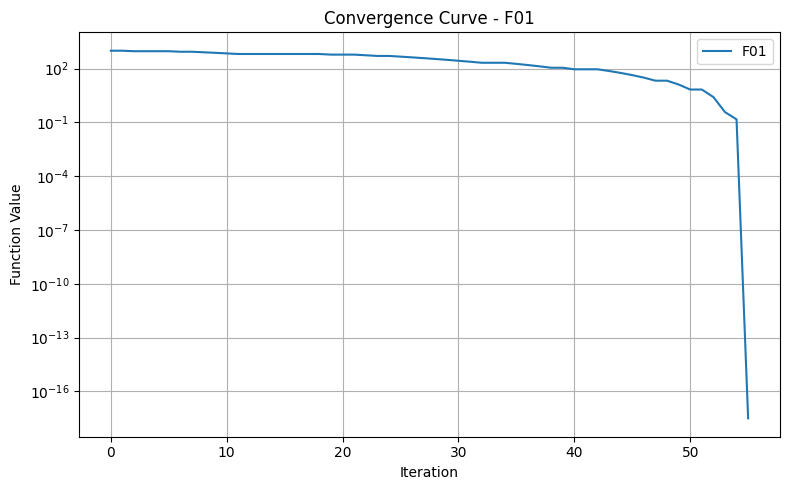

Running F02 (dim=30)...


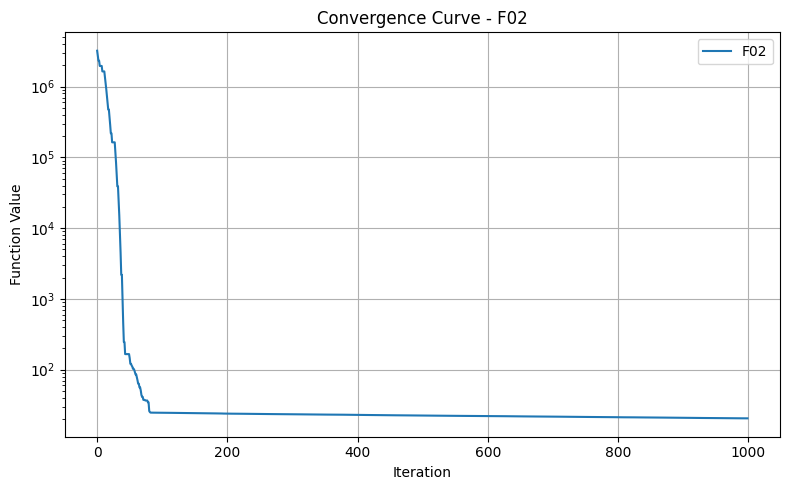

Running F03 (dim=30)...


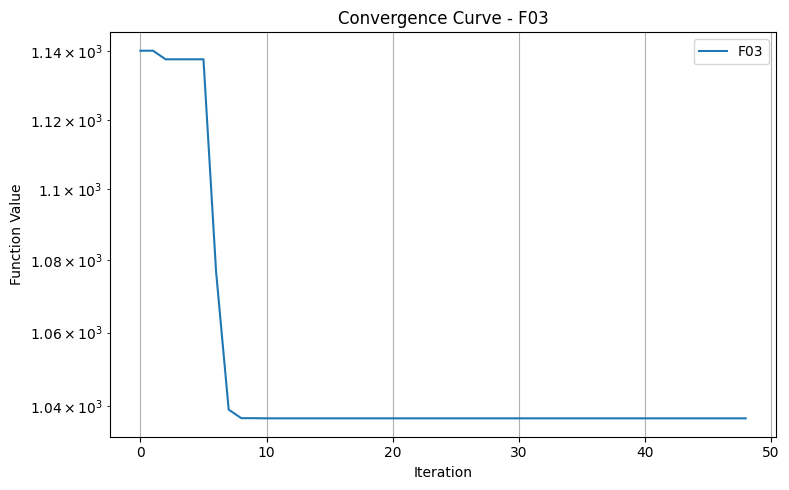

Running F04 (dim=30)...


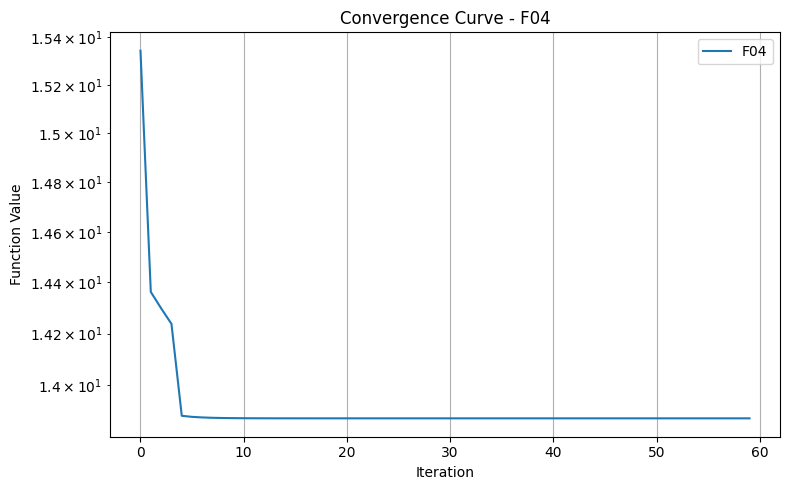

Running F05 (dim=30)...


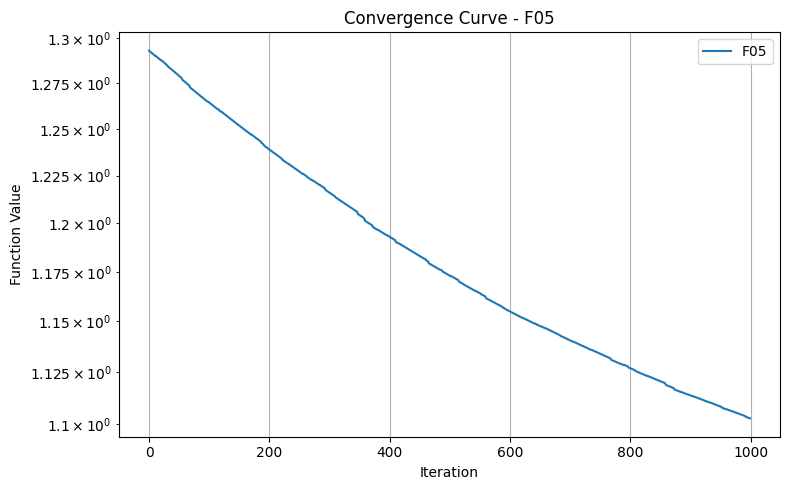

Running F06 (dim=30)...


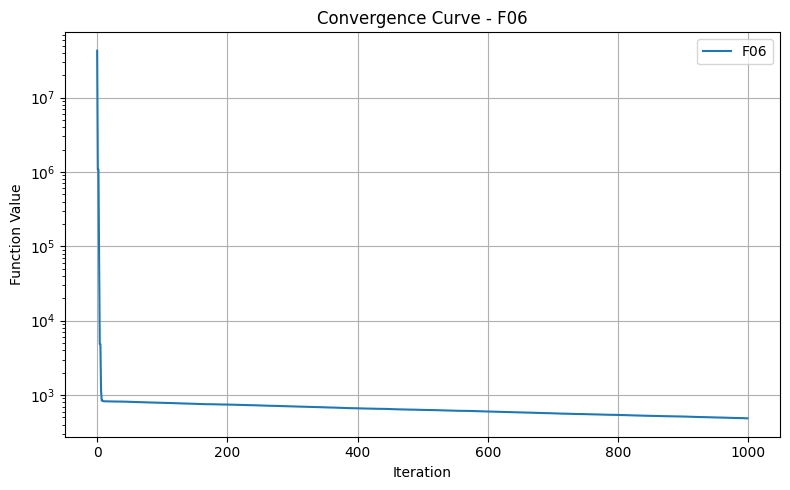

Running F07 (dim=30)...


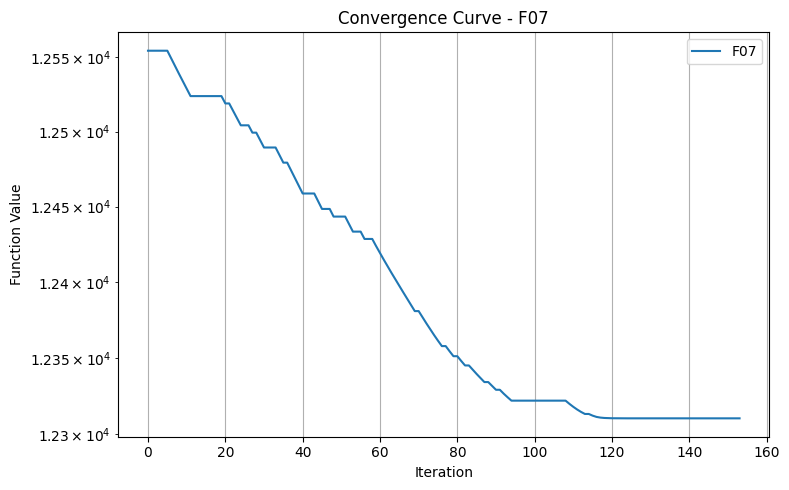

Running F08 (dim=30)...


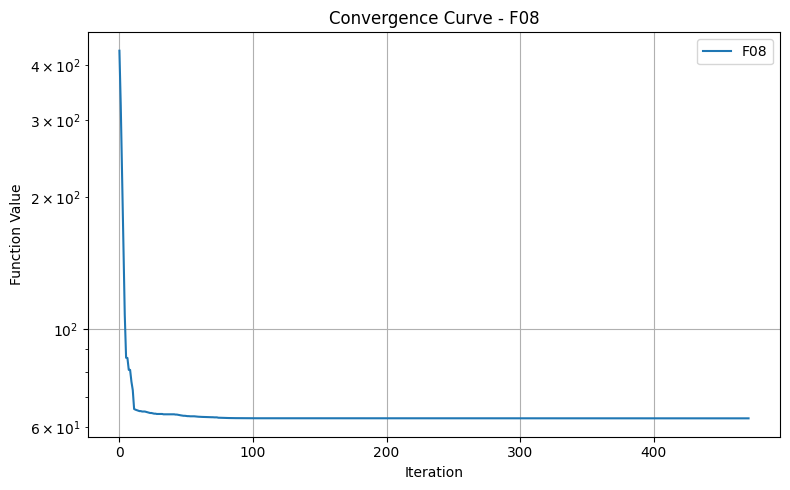

Running F09 (dim=30)...


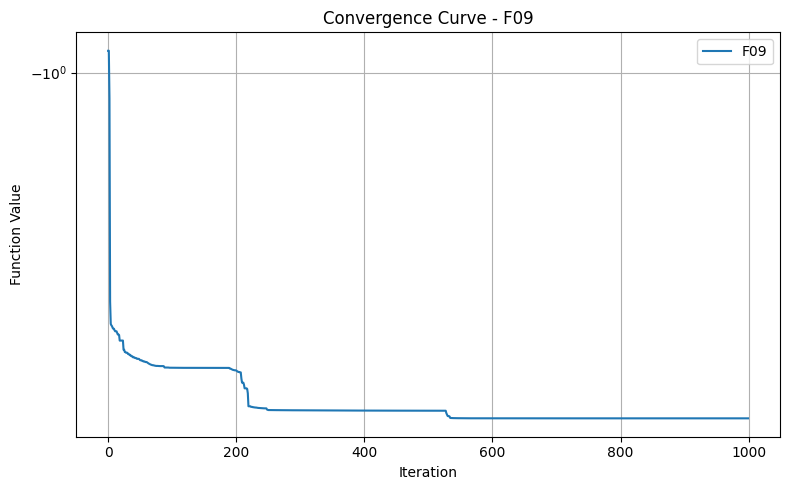

Running F10 (dim=30)...


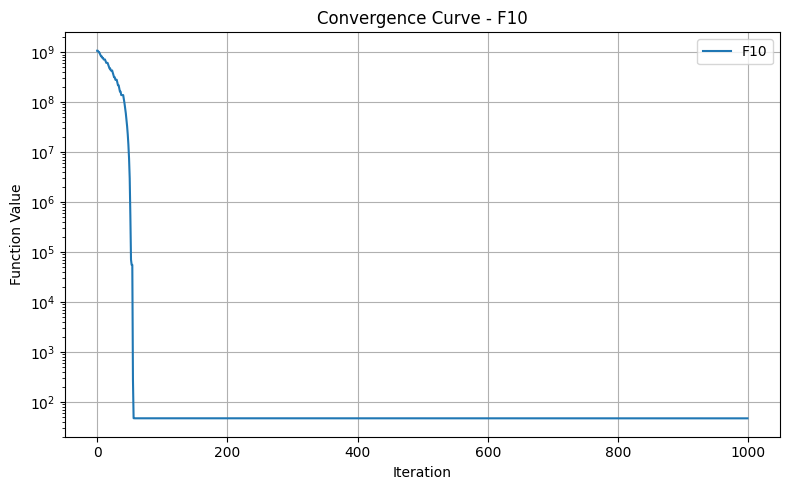

Running F11 (dim=30)...


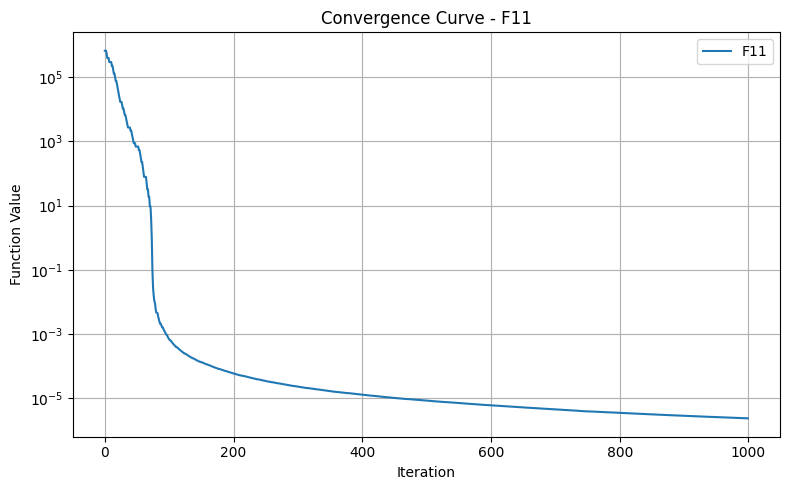

Running F12 (dim=30)...


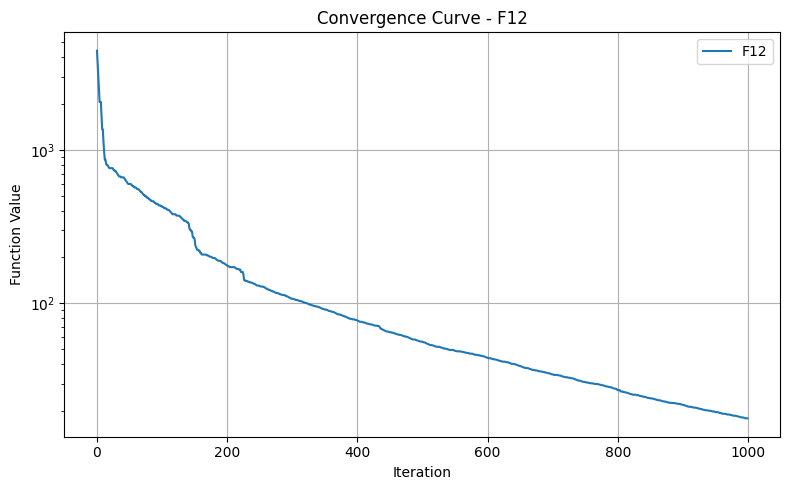

Running F13 (dim=30)...


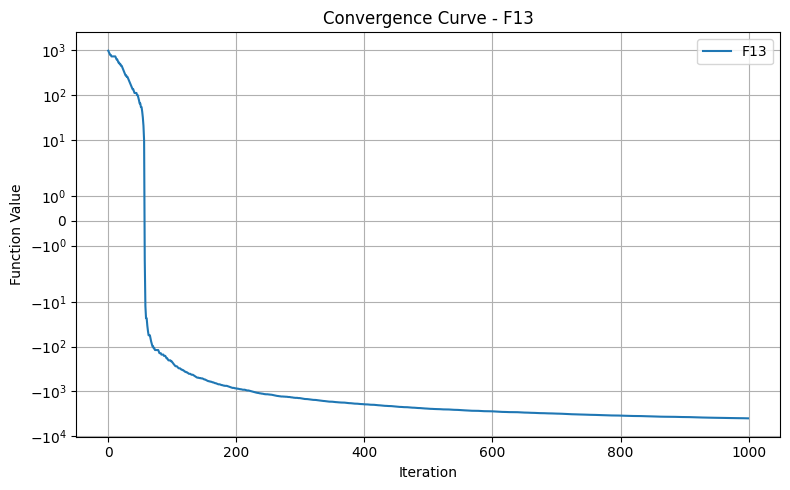

Running F14 (dim=30)...


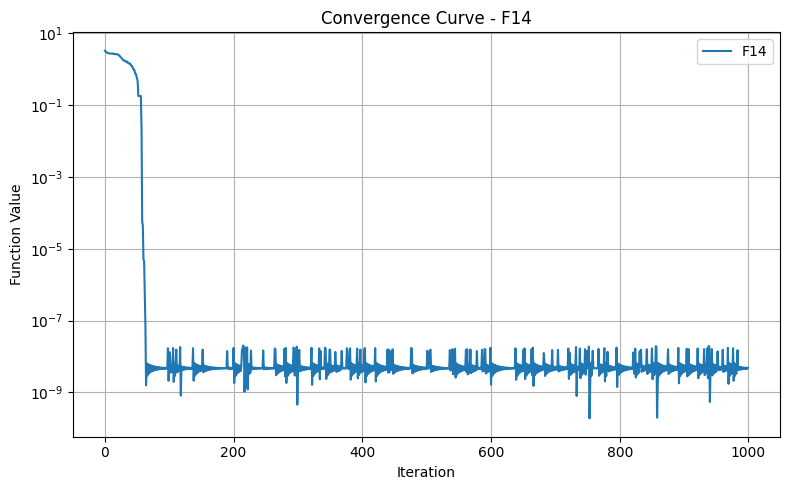

Running F15 (dim=30)...


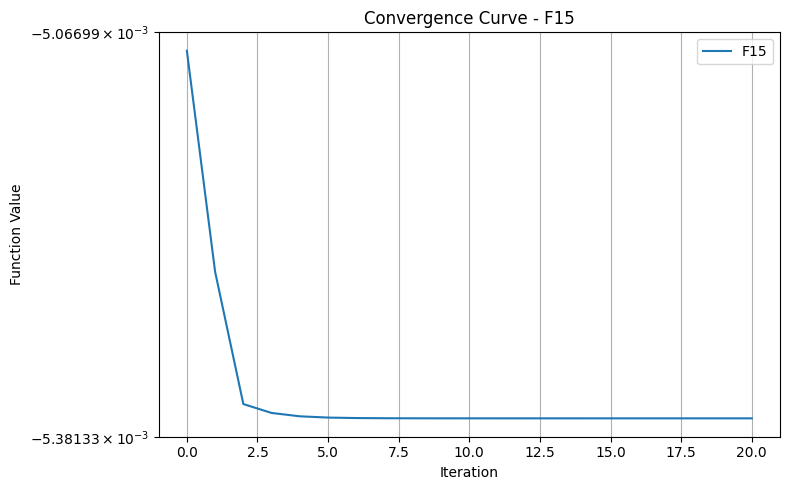

Running F16 (dim=2)...
Running F17 (dim=2)...


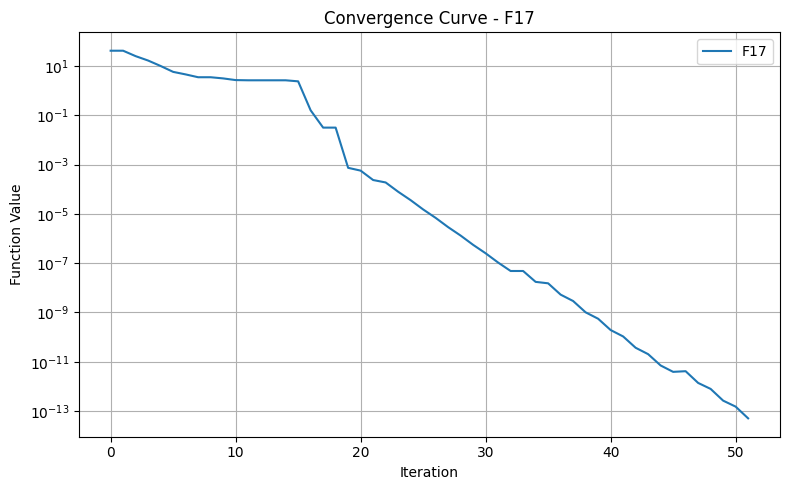

Running F18 (dim=2)...


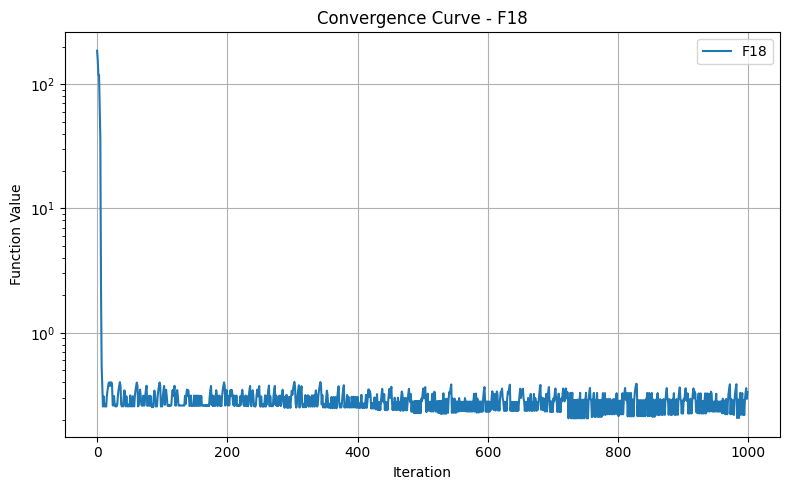

Running F19 (dim=2)...


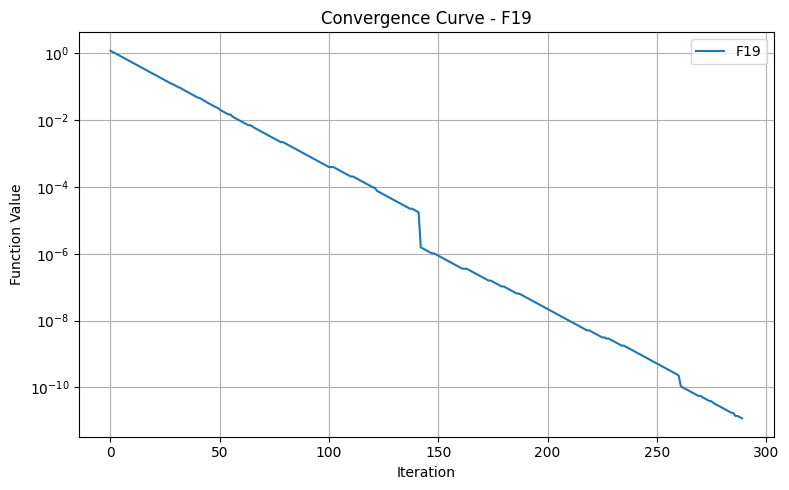

Running F20 (dim=2)...


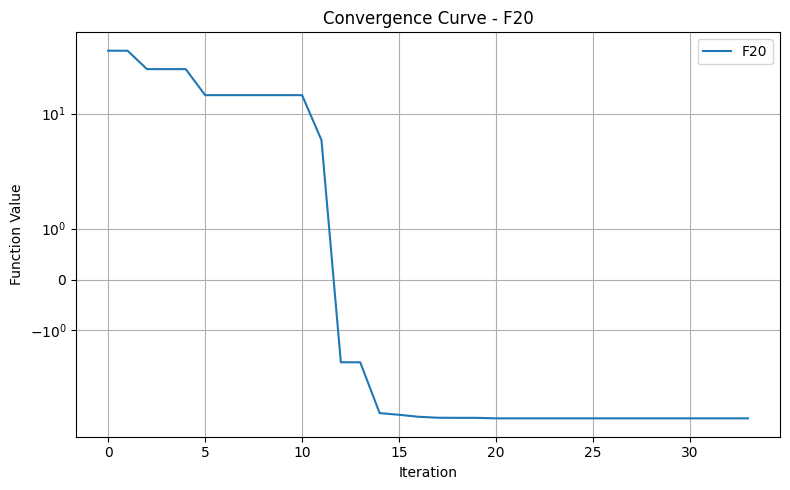

Running F21 (dim=2)...


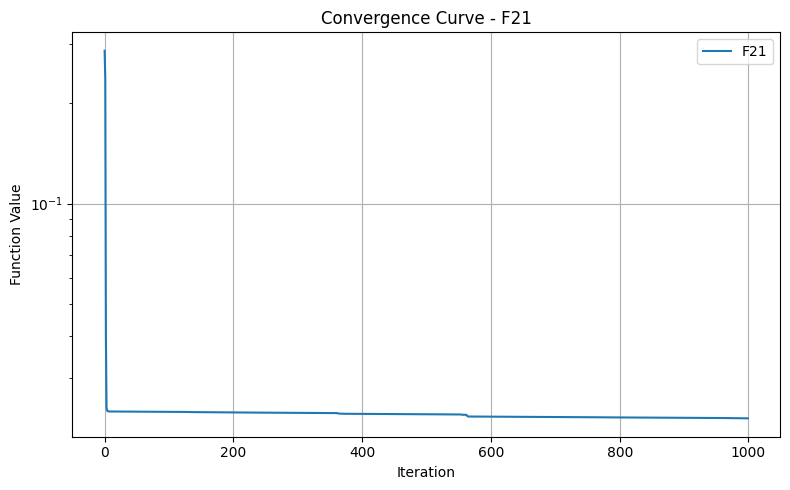

Running F22 (dim=2)...


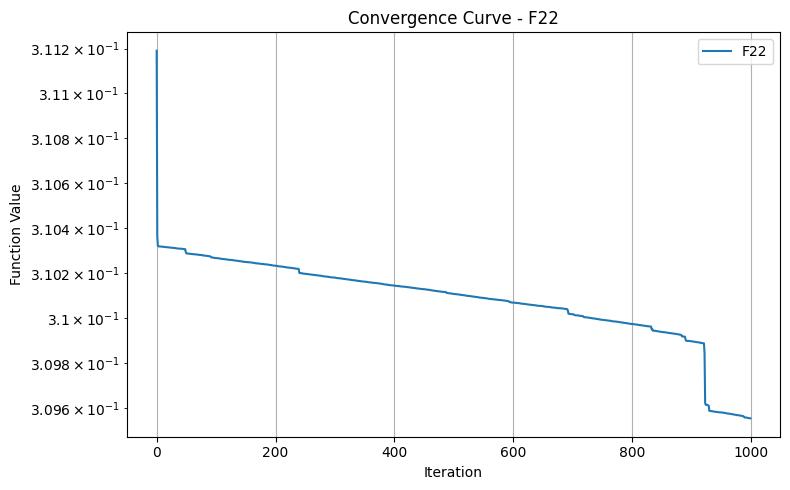

Running F23 (dim=2)...


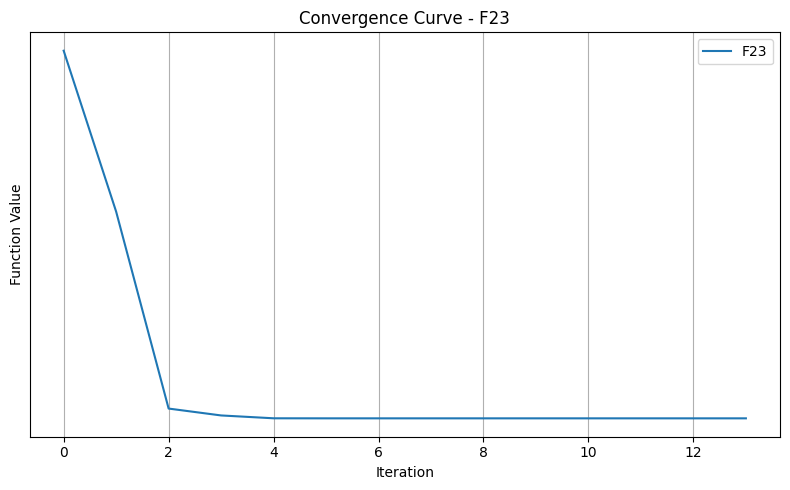


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       1.323567e-23  1.793240e-18  1.925972e-19  1.491719e-17  3.182786e-18
F02       2.043924e+01  2.233892e+01  2.212603e+01  2.752535e+01  1.284328e+00
F03       6.825275e+02  9.975867e+02  1.014832e+03  1.394891e+03  1.647512e+02
F04       1.231404e+01  1.366761e+01  1.365468e+01  1.479506e+01  5.694191e-01
F05       1.053689e+00  1.082156e+00  1.081086e+00  1.107772e+00  1.293050e-02
F06       3.561529e+02  5.356458e+02  5.147156e+02  7.702931e+02  1.034870e+02
F07       1.218934e+04  1.231084e+04  1.231016e+04  1.241085e+04  5.237942e+01
F08       3.930743e+01  6.089709e+01  6.120277e+01  8.258515e+01  1.100011e+01
F09      -9.084337e+00 -5.282221e+00 -5.322263e+00 -2.336923e+00  1.251935e+00
F10       4.668601e-03  4.103985e+01  3.539373e+01  9.866433e+01  3.351878e+01
F11       2.035074e-06  2

In [1]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
from scipy.optimize import minimize, Bounds

# --- Benchmark Functions (F1–F23) ---
def F1(x): return np.sum(x**2)
def F2(x): return np.sum(100 * (x[1:] - x[:-1]**2)**2 + (x[:-1] - 1)**2)
def F3(x): return np.sum(x**2 - 10 * np.cos(2 * np.pi * x) + 10)
def F4(x): return -20 * np.exp(-0.2*np.sqrt(np.mean(x**2))) - np.exp(np.mean(np.cos(2*np.pi*x))) + 20 + np.e
def F5(x): return np.sum(x**2)/4000 - np.prod(np.cos(x / np.sqrt(np.arange(1, len(x)+1)))) + 1
def F6(x): return np.sum(x**2) + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**2 + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**4
def F7(x): return 418.9829 * len(x) - np.sum(x * np.sin(np.sqrt(np.abs(x))))
def F8(x): 
    w = 1 + (x - 1) / 4
    return np.sin(np.pi * w[0])**2 + np.sum((w[:-1] - 1)**2 * (1 + 10*np.sin(np.pi*w[:-1] + 1)**2)) + (w[-1]-1)**2 * (1 + np.sin(2*np.pi*w[-1])**2)
def F9(x): return -np.sum(np.sin(x) * np.sin(((np.arange(1, len(x)+1) * x**2) / np.pi))**20)
def F10(x): return x[0]**2 + 1e6 * np.sum(x[1:]**2)
def F11(x): return np.sum(np.abs(x)**(2 + 4*np.arange(len(x))/(len(x)-1)))
def F12(x): return np.sum([np.sum(x[:i])**2 for i in range(1, len(x)+1)])
def F13(x): return np.sum((x - 1)**2) - np.sum(x[:-1] * x[1:])
def F14(x): return 1 - np.cos(2*np.pi*np.sqrt(np.sum(x**2))) + 0.1*np.sqrt(np.sum(x**2))
def F15(x): return - (1 + np.cos(12*np.sqrt(np.sum(x**2)))) / (0.5*np.sum(x**2) + 2)
def F16(x): return -np.cos(x[0]) * np.cos(x[1]) * np.exp(-(x[0]-np.pi)**2 - (x[1]-np.pi)**2)
def F17(x): return (x[0] + 2*x[1] - 7)**2 + (2*x[0] + x[1] - 5)**2
def F18(x): return 100*np.sqrt(abs(x[1] - 0.01*x[0]**2)) + 0.01*abs(x[0] + 10)
def F19(x): return 0.26*(x[0]**2 + x[1]**2) - 0.48*x[0]*x[1]
def F20(x): return np.sin(x[0]+x[1]) + (x[0]-x[1])**2 - 1.5*x[0] + 2.5*x[1] + 1
def F21(x): return 0.5 + (np.sin(x[0]**2 - x[1]**2)**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F22(x): return 0.5 + (np.cos(np.sin(abs(x[0]**2 - x[1]**2)))**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F23(x): 
    r = np.sqrt(x[0]**2 + x[1]**2)
    z = np.clip(abs(1 - r / np.pi), -50, 50)
    try:
        exp_term = np.exp(z)
    except:
        exp_term = 1e10
    return -abs(np.sin(x[0]) * np.cos(x[1]) * exp_term)

benchmark_functions = {
    f"F{str(i+1).zfill(2)}": f for i, f in enumerate([
        F1, F2, F3, F4, F5, F6, F7, F8, F9, F10, F11, F12, F13, F14, F15,
        F16, F17, F18, F19, F20, F21, F22, F23
    ])
}

# ----- Numerical Gradient -----
def numerical_gradient(func, x, eps=1e-8):
    grad = np.zeros_like(x)
    for i in range(len(x)):
        x1 = np.copy(x)
        x2 = np.copy(x)
        x1[i] += eps
        x2[i] -= eps
        f1 = func(x1)
        f2 = func(x2)
        if np.isfinite(f1) and np.isfinite(f2):
            grad[i] = (f1 - f2) / (2 * eps)
        else:
            grad[i] = 0  # safe fallback
    return grad

# ----- Powell's Dog Leg with Chaos -----
def powells_dog_leg_with_chaos(func, grad_func, x0, trust_radius=1.0, tol=1e-6, max_iter=1000, chaotic_prob=0.1):
    x = x0.copy()
    convergence_curve = []
    for _ in range(max_iter):
        grad = grad_func(x)
        if np.linalg.norm(grad) < tol:
            break

        hess = np.eye(len(x))  # Identity Hessian
        newton_step = -np.linalg.solve(hess, grad)
        cauchy_point = -trust_radius * grad / np.linalg.norm(grad)

        if np.linalg.norm(newton_step) <= trust_radius:
            p = newton_step
        elif np.linalg.norm(cauchy_point) >= trust_radius:
            p = cauchy_point
        else:
            u = cauchy_point - newton_step
            a = np.dot(u, u)
            b = 2 * np.dot(u, newton_step)
            c = np.dot(newton_step, newton_step) - trust_radius**2
            discriminant = b**2 - 4 * a * c

            if not np.isfinite(discriminant) or discriminant < 0:
                p = cauchy_point
            else:
                tau = (-b + np.sqrt(discriminant)) / (2 * a)
                p = newton_step + tau * u

        if random.random() < chaotic_prob:
            chaos = np.random.rand(len(x))
            p += (chaos - 0.5) * 0.1

        alpha = 1.0
        while func(x + alpha * p) > func(x) + 1e-4 * alpha * np.dot(grad, p):
            alpha *= 0.5
            if alpha < 1e-6:
                break

        x = x + alpha * p
        convergence_curve.append(func(x))

    return x, convergence_curve

# ----- Run Single Benchmark -----
def run_benchmark(func, dim, runs=30, low=-10, high=10):
    results = []
    convergence = None
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, curve = powells_dog_leg_with_chaos(func, lambda x: numerical_gradient(func, x), x0)
            val = func(result)
            if np.isfinite(val):
                results.append(val)
                if convergence is None:
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    for name, func in benchmark_functions.items():
        d = 2 if name in ['F16','F17','F18','F19','F20','F21','F22','F23'] else dim
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# Save Excel
results.to_excel('Benchmark_IP-C-PDL.xlsx')
print("\n✅ Results saved to Benchmark_IP-C-PDL.xlsx")